# Investigate Hotel Business using Data Visualization

**Name:** Nandini Sharma
**Date:** 19-10-2026

# Stage 0: Problem Statement

**0.1 Why is it important to understand customer booking behaviour?**

A hotel earns money only when its rooms are used. An empty room today cannot be sold again tomorrow. If the hotel knows when people book, how long they stay and when they cancel, it can plan better. This helps to decide room prices, how many staff are needed, how many extra rooms to sell (overbooking), when to give offers, and what cancellation rules to keep.

**0.2 The three business questions (in my words)**
1. Which hotel do people book more, City Hotel or Resort Hotel?
2. Do people who stay for more nights cancel more or less?
3. Do people who book very early (long before arrival) cancel more or less?

**0.3 Objective**

To find out from the data why bookings get cancelled and when the hotel is busy, and then give simple advice to the hotel manager to reduce cancellations and get more bookings.

# Stage 1: Data Preprocessing
## 1.1 Data Overview

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("hotel_bookings_data.csv")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Rows: 119390
Columns: 29


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_weekdays_nights,adults,...,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status
0,Resort Hotel,0,342,2017,September,27,1,0,0,2,...,3,No Deposit,NaN,NaN,0,Personal,0.0,0,0,Check-Out
1,Resort Hotel,0,737,2017,September,27,1,0,0,2,...,4,No Deposit,NaN,NaN,0,Personal,0.0,0,0,Check-Out
2,Resort Hotel,0,7,2017,September,27,1,0,1,1,...,0,No Deposit,NaN,NaN,0,Personal,75.0,0,0,Check-Out
3,Resort Hotel,0,13,2017,September,27,1,0,1,1,...,0,No Deposit,304.0,NaN,0,Personal,75.0,0,0,Check-Out
4,Resort Hotel,0,14,2017,September,27,1,0,2,2,...,0,No Deposit,240.0,NaN,0,Personal,98.0,0,1,Check-Out


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 29 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_weekdays_nights        119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [7]:
print("First year:", df["arrival_date_year"].min())
print("Last year:", df["arrival_date_year"].max())

First year: 2017
Last year: 2019


The data has **119,390 rows and 29 columns**. It covers bookings from **2017 to 2019**. Each row is one booking.

Important columns for this project:
- `hotel` : City Hotel or Resort Hotel
- `is_canceled` : 1 means the booking was cancelled, 0 means it was not cancelled
- `lead_time` : number of days between booking and arrival
- `stays_in_weekend_nights` and `stays_in_weekdays_nights` : number of nights stayed (I will add them to get the total stay)
- `arrival_date_month` : month of arrival

## 1.2 Data Assessment
### Missing values

In [8]:
raw = pd.read_csv("hotel_bookings_data.csv")
raw.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_weekdays_nights               0
adults                                 0
children                               4
babies                                 0
meal                                   0
city                                 488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
booking_changes                        0
deposit_type                           0
agent                              16340
company                           112593
days_in_waiting_list                   0
customer_type   

In [9]:
# fill the missing values
df["children"] = df["children"].fillna(0)
df["agent"] = df["agent"].fillna(0)
df["company"] = df["company"].fillna(0)
df["city"] = df["city"].fillna("Unknown")

# check again
df.isnull().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_weekdays_nights          0
adults                            0
children                          0
babies                            0
meal                              0
city                              0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests   

Four columns had missing values: `company`, `agent`, `city` and `children`. This is how I handled them:

- **children** (4 missing): filled with **0**. It means the guest did not bring any children.
- **agent** (16,340 missing): filled with **0**. It means no travel agent was used, so the guest booked directly.
- **company** (112,593 missing): filled with **0**. It means the booking was not made by a company. Most bookings are personal, so this is normal.
- **city** (488 missing): filled with **"Unknown"**, because we do not know where the guest is from.

### Duplicate rows

In [10]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Rows left:", len(df))

Duplicate rows: 33261
Rows left: 86129


There are **33,261 duplicate rows**. I removed them. If two rows are exactly same in all columns, they are most likely the same booking saved two times. If I keep them, the same booking will be counted two times and the results will be wrong.

### Unclear values

In [11]:
df["meal"].value_counts()

meal
Breakfast     67088
No Meal        9442
Dinner         8798
Undefined       454
Full Board      347
Name: count, dtype: int64

In [12]:
# Undefined means no meal was chosen, so I put it in No Meal
df["meal"] = df["meal"].replace("Undefined", "No Meal")
df["meal"].value_counts()

meal
Breakfast     67088
No Meal        9896
Dinner         8798
Full Board      347
Name: count, dtype: int64

The `meal` column has a value **Undefined**. This means no meal plan was given for that booking. This is same as having no meal, so I changed **Undefined** to **No Meal**.

### Wrong or extreme values

In [13]:
# add up the guests in each booking
df["total_guests"] = df["adults"] + df["children"] + df["babies"]

# count the wrong values
print("Negative price:", (df["adr"] < 0).sum())
print("Zero guests:", (df["total_guests"] == 0).sum())
print("Highest price:", df["adr"].max())
print("99% of prices are below:", df["adr"].quantile(0.99))


Negative price: 1
Zero guests: 165
Highest price: 5400.0
99% of prices are below: 262.0


In [14]:
# remove the wrong rows
df = df[df["adr"] >= 0]
df = df[df["total_guests"] > 0]
df = df[df["adr"] <= df["adr"].quantile(0.99)]

print("Rows left:", len(df))

Rows left: 85122


*Caption: The boxplot shows a few very high prices far away from the others.*

What I removed and why:
- **1 row with negative adr.** Price cannot be negative.
- **165 rows with 0 guests.** A booking with no guest is not a real stay.
- **841 rows with very high adr** (above the 99th percentile, which is 262). The highest price is 5,400, which is too far from normal and would spoil the average.

I kept the rows where adr is 0, because they can be free or complimentary stays, and they are still real bookings.

After cleaning, **85,122 rows** are left.

In [15]:
# new column for total nights
df["total_stay"] = df["stays_in_weekend_nights"] + df["stays_in_weekdays_nights"]

# list of months in correct order
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]

# Stage 2: Data Analysis
## 2.1 Monthly Booking Analysis by Hotel Type

### Which hotel is booked more?

hotel
City Hotel      52216
Resort Hotel    32906
Name: count, dtype: int64
hotel
City Hotel      61.342544
Resort Hotel    38.657456
Name: count, dtype: float64


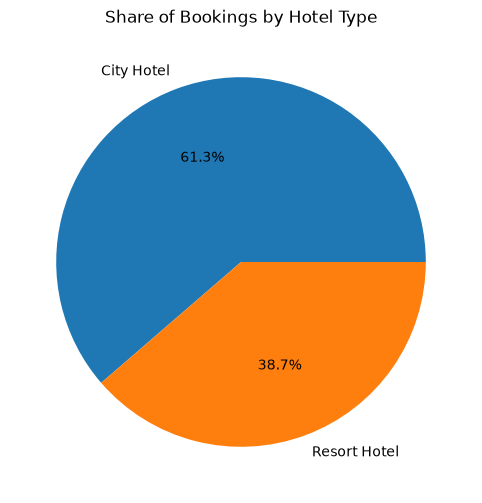

In [16]:
hotel_count = df["hotel"].value_counts()
print(hotel_count)
print(hotel_count / len(df) * 100)

plt.figure(figsize=(6, 6))
plt.pie(hotel_count, labels=hotel_count.index, autopct="%1.1f%%")
plt.title("Share of Bookings by Hotel Type")
plt.show()

*Caption: The pie chart shows the share of bookings for each hotel type.*

**Answer:** City Hotel is booked more. It has **61.3%** of the bookings and Resort Hotel has **38.7%**. So City Hotel has about **22.6 percentage points** more share than Resort Hotel.

### Bookings per month

arrival_date_month
January      2875
February     2960
March        2691
April        3541
May          4794
June         5007
July         5290
August       4895
September    5635
October      6441
November     4044
December     4043
Name: count, dtype: int64
arrival_date_month
January      2026
February     2070
March        1932
April        2474
May          2612
June         2775
July         2897
August       2718
September    4140
October      4214
November     2390
December     2658
Name: count, dtype: int64


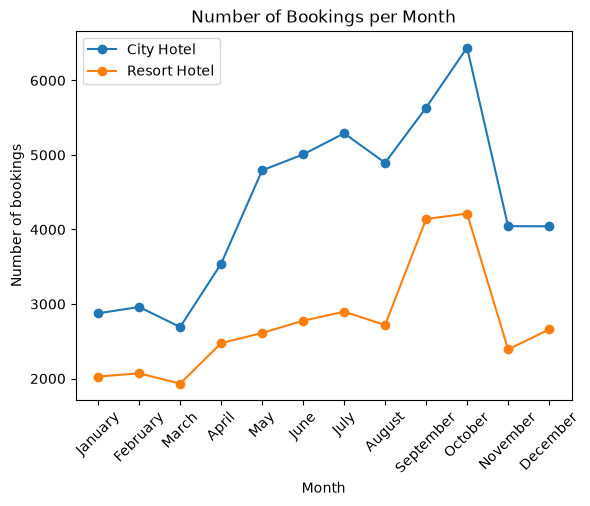

In [36]:
# split the data into two hotels
city = df[df["hotel"] == "City Hotel"]
resort = df[df["hotel"] == "Resort Hotel"]

# count the bookings in each month
city_count = city["arrival_date_month"].value_counts()
resort_count = resort["arrival_date_month"].value_counts()

# put the months in the right order
city_count = city_count.reindex(month_order)
resort_count = resort_count.reindex(month_order)

print(city_count)
print(resort_count)

# draw the chart
plt.plot(month_order, city_count, marker="o", label="City Hotel")
plt.plot(month_order, resort_count, marker="o", label="Resort Hotel")
plt.title("Number of Bookings per Month")
plt.xlabel("Month")
plt.ylabel("Number of bookings")
plt.xticks(rotation=45)
plt.legend()
plt.show()

*Caption: Total bookings in each month for both hotels.*

In this chart, **October** looks the busiest (City 6,441, Resort 4,214) and **March** is the quietest (City 2,691, Resort 1,932).

But there is a problem. September and October have data of **3 years**, and all other months have data of only **2 years**. So September and October look bigger only because they have one extra year. To compare in a fair way, I will take the average per year in the next chart.

arrival_date_month
April        2
August       2
December     2
February     2
January      2
July         2
June         2
March        2
May          2
November     2
October      3
September    3
Name: arrival_date_year, dtype: int64
hotel               City Hotel  Resort Hotel
arrival_date_month                          
April                   1770.0        1237.0
August                  2448.0        1359.0
December                2022.0        1329.0
February                1480.0        1035.0
January                 1438.0        1013.0
July                    2645.0        1448.0
June                    2504.0        1388.0
March                   1346.0         966.0
May                     2397.0        1306.0
November                2022.0        1195.0
October                 2147.0        1405.0
September               1878.0        1380.0


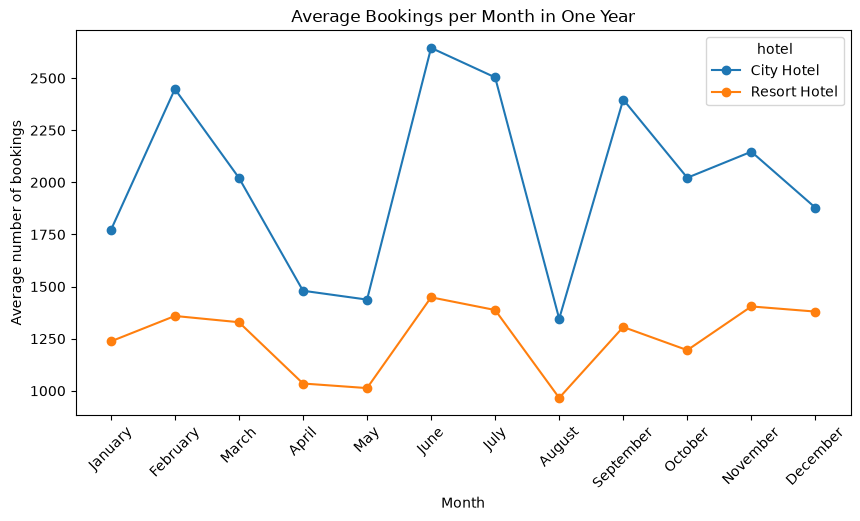

In [37]:
# how many years of data each month has
years_in_month = df.groupby("arrival_date_month")["arrival_date_year"].nunique()
print(years_in_month)

# average bookings per year
average = monthly.div(years_in_month, axis=0)
print(average.round(0))

average.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Average Bookings per Month in One Year")
plt.xlabel("Month")
plt.ylabel("Average number of bookings")
plt.xticks(range(12), month_order, rotation=45)
plt.show()

*Caption: Average bookings in one year for each month. This is fair because every month now has the same one-year basis.*

**Busiest and quietest months**
- City Hotel: busiest in **July** (about 2,645), then June and August. Quietest in **March** (about 1,346) and January.
- Resort Hotel: busiest in **July** (about 1,448), then October and September. Quietest in **March** (about 966), then January and February.
- The Resort Hotel line is flatter (about 970 to 1,450). The City Hotel line goes up and down much more (about 1,350 to 2,650).

**Why does this happen?** (these are my ideas, the data does not prove them)
- Summer months have school holidays and good weather, so many people travel. This can be the reason for the July peak.
- City Hotel bookings stay high in November and December too (about 2,020). This may be because of business trips, office events or festival travel.
- Resort Hotel is flatter, so its guests may travel in all seasons.
- January to March is cold and has few holidays, so there are fewer bookings.

**What can the hotel do?**
- Increase room prices in the busy months (June to August) and give offers in the quiet months (January to March).
- Keep more staff in summer and fewer staff in quiet months.
- Do repairs and maintenance work in March, when fewer guests come.
- Spend the advertising money on the quiet months to fill the rooms.

## 2.2 Impact of Stay Duration on Cancellation Rate

### Cancellation rate for each hotel

hotel
City Hotel      30.201471
Resort Hotel    23.241962
Name: is_canceled, dtype: float64


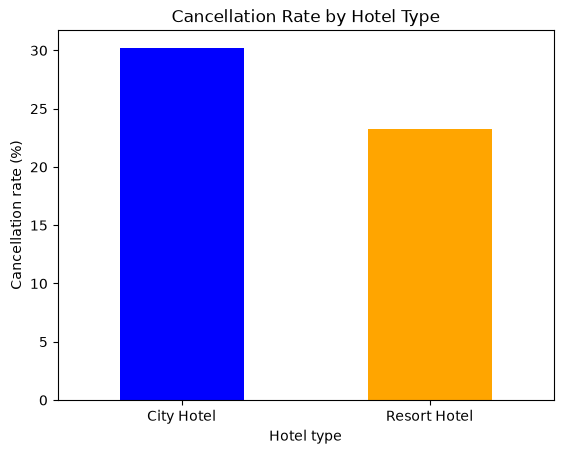

In [24]:
cancel_rate = df.groupby("hotel")["is_canceled"].mean() * 100
print(cancel_rate)

cancel_rate.plot(kind="bar", color=["blue", "orange"])
plt.title("Cancellation Rate by Hotel Type")
plt.xlabel("Hotel type")
plt.ylabel("Cancellation rate (%)")
plt.xticks(rotation=0)
plt.show()

*Caption: Percentage of bookings that were cancelled in each hotel.*

**Answer:** City Hotel is cancelled more. Its cancellation rate is **30.2%** and for Resort Hotel it is **23.2%**. The difference is about **7 percentage points**.

### Cancellation rate and length of stay

hotel       City Hotel  Resort Hotel
total_stay                          
0                  5.6           2.8
1                 22.3          12.4
2                 29.8          20.4
3                 31.4          25.5
4                 32.2          26.7
5                 30.3          30.2
6                 37.3          31.2
7                 37.7          28.1
8                 46.0          33.1
9                 43.6          31.9
10                58.1          24.7
11                58.7          21.7
12                48.3          35.8
13                61.5          25.6
14                69.8          20.4
15                64.9          31.2


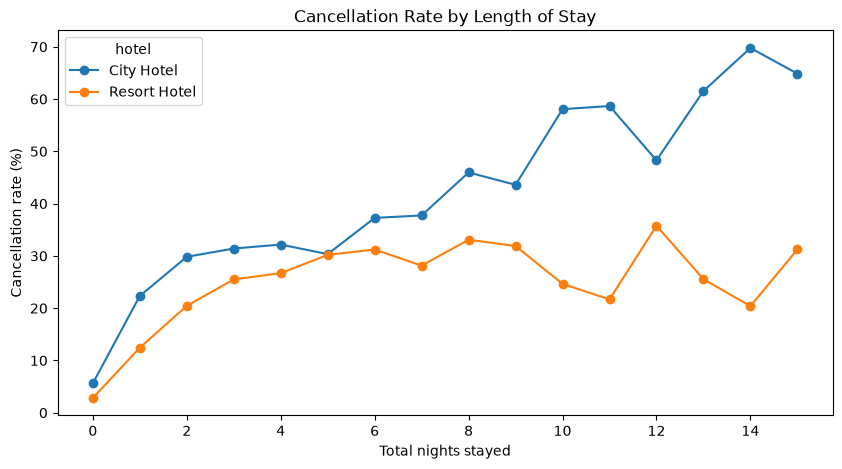

In [25]:
# only stays up to 15 nights, because very long stays have very few bookings
short = df[df["total_stay"] <= 15]

stay_rate = short.groupby(["total_stay", "hotel"])["is_canceled"].mean().unstack() * 100
print(stay_rate.round(1))

stay_rate.plot(kind="line", marker="o", figsize=(10, 5))
plt.title("Cancellation Rate by Length of Stay")
plt.xlabel("Total nights stayed")
plt.ylabel("Cancellation rate (%)")
plt.show()

*Caption: Cancellation rate for stays of 0 to 15 nights. For long stays the number of bookings is small, so the line goes up and down and is less reliable there.*

**Trend:**
- **City Hotel:** the cancellation rate keeps going up when the stay gets longer. It is about 6% for 0 nights, 22% for 1 night, about 31% for 3 to 5 nights, about 38% for 7 nights, and about 44% to 70% for 8 nights or more.
- **Resort Hotel:** it also goes up in the beginning (3% for 0 nights, about 30% for 5 to 6 nights), but after that it stays almost same, between 20% and 35%.

**Is the relationship positive, negative or flat?** It is **positive** for both hotels, which means longer stays are cancelled more. But it is different in the two hotels. City Hotel keeps going up, and Resort Hotel becomes almost flat after 5 nights.

**Possible reasons why longer stays are cancelled more:**
1. A long trip needs more money and more planning, so there is more chance that something changes (work, health, family).
2. People who plan a long stay usually book early. The table below shows this. Booking early also has a higher chance of cancelling (see section 2.3).
3. Short stays are often booked at the last moment when the plan is already fixed, so they are cancelled less.

In [32]:
# are long stays booked earlier?
df["stay_group"] = pd.cut(df["total_stay"], [-1, 1, 3, 7, 14, 100],
                          labels=["0-1", "2-3", "4-7", "8-14", "15+"])
df.groupby(["stay_group", "hotel"])["lead_time"].mean().unstack().round(0)

hotel,City Hotel,Resort Hotel
stay_group,,
0-1,39.0,19.0
2-3,81.0,56.0
4-7,94.0,115.0
8-14,104.0,155.0
15+,51.0,146.0


*Caption: Average lead time (days) for each group of stay length.*

The table shows that very short stays (0 to 1 nights) are booked only about 39 days (City) and 19 days (Resort) before arrival. Longer stays of 2 to 14 nights are booked about 56 to 155 days before. So longer stays are booked earlier. The only exception is the small group of 15+ nights in City Hotel.

## 2.3 Impact of Lead Time on Cancellation Rate

**Lead time** is the number of days between the day the guest makes the booking and the day the guest arrives. If someone books today for tomorrow, the lead time is 1. If someone books one year before, the lead time is about 365.

lead_group
0-7        10.5
8-30       27.9
31-90      33.4
91-180     36.8
181-365    45.2
365+       52.8
Name: is_canceled, dtype: float64
lead_group
0-7         5.9
8-30       20.6
31-90      29.6
91-180     31.7
181-365    34.6
365+       20.9
Name: is_canceled, dtype: float64
lead_group
0-7         9680
8-30       10342
31-90      14832
91-180     11315
181-365     5693
365+         354
dtype: int64
lead_group
0-7        8281
8-30       5627
31-90      7249
91-180     6464
181-365    5113
365+        172
dtype: int64


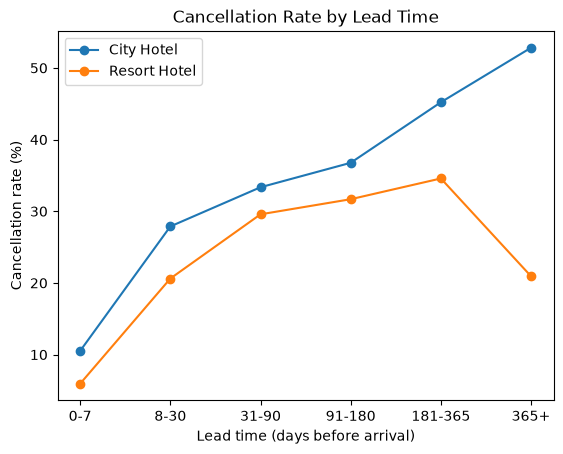

In [38]:
# put lead time into groups
bins = [-1, 7, 30, 90, 180, 365, 1000]
names = ["0-7", "8-30", "31-90", "91-180", "181-365", "365+"]
df["lead_group"] = pd.cut(df["lead_time"], bins, labels=names)

# split the data into two hotels
city = df[df["hotel"] == "City Hotel"]
resort = df[df["hotel"] == "Resort Hotel"]

# cancellation rate for each group
city_rate = city.groupby("lead_group")["is_canceled"].mean() * 100
resort_rate = resort.groupby("lead_group")["is_canceled"].mean() * 100
print(city_rate.round(1))
print(resort_rate.round(1))

# number of bookings in each group
print(city.groupby("lead_group").size())
print(resort.groupby("lead_group").size())

# draw the chart
plt.plot(names, city_rate, marker="o", label="City Hotel")
plt.plot(names, resort_rate, marker="o", label="Resort Hotel")
plt.title("Cancellation Rate by Lead Time")
plt.xlabel("Lead time (days before arrival)")
plt.ylabel("Cancellation rate (%)")
plt.legend()
plt.show()

*Caption: Cancellation rate for each lead time group. The last group (365+) has very few bookings (354 City, 172 Resort), so it is not very reliable.*

**Lowest and highest cancellation**
- It is **lowest for 0 to 7 days**: **10.5%** for City Hotel and **5.9%** for Resort Hotel.
- **City Hotel** is **highest at 365+ days (52.8%)**. It is also high at 181 to 365 days (45.2%), and this group has 5,693 bookings, so it is reliable.
- **Resort Hotel** is **highest at 181 to 365 days (34.6%)**.

**Comparing the two hotels**
- City Hotel has a higher cancellation rate than Resort Hotel at every lead time.
- City Hotel keeps going up at every step (10.5%, 27.9%, 33.4%, 36.8%, 45.2%, 52.8%).
- Resort Hotel goes up fast in the beginning (5.9% to 29.6%) but then stays more stable at about 30% to 35%. After 365 days it goes down to 20.9%, but there are only 172 bookings, so I will not trust this too much.
- So Resort Hotel is more stable, and City Hotel keeps rising.

### Why is City Hotel different? (booking channel)

hotel           City Hotel  Resort Hotel
market_segment                          
Aviation              19.9           NaN
Complementary         11.0          16.5
Corporate             11.7          12.4
Direct                16.3          13.0
Groups                35.8          19.6
Offline TA/TO         17.5          12.1
Online TA             36.0          33.5


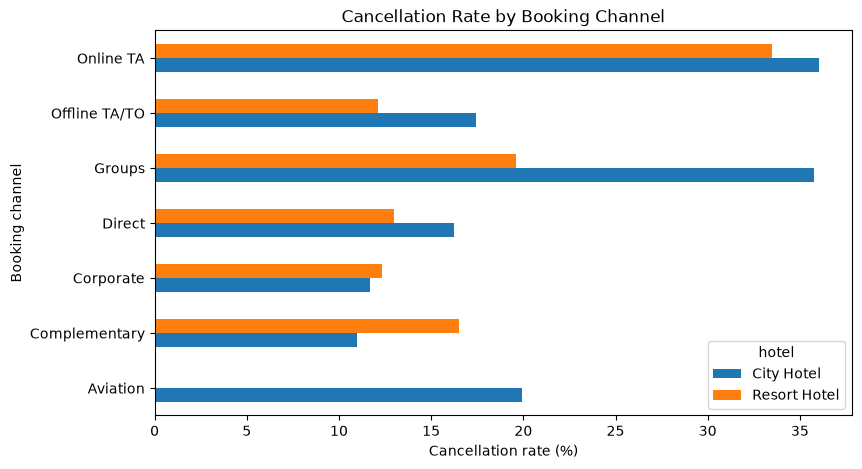

market_segment
Online TA        0.664
Offline TA/TO    0.132
Direct           0.104
Groups           0.045
Corporate        0.042
Complementary    0.009
Aviation         0.004
Undefined        0.000
Name: proportion, dtype: float64


In [33]:
# cancellation rate by booking channel (market segment)
data = df[df["market_segment"] != "Undefined"]
channel = data.groupby(["market_segment", "hotel"])["is_canceled"].mean().unstack() * 100
print(channel.round(1))

channel.plot(kind="barh", figsize=(9, 5))
plt.title("Cancellation Rate by Booking Channel")
plt.xlabel("Cancellation rate (%)")
plt.ylabel("Booking channel")
plt.show()

# share of bookings for each channel in City Hotel
city = df[df["hotel"] == "City Hotel"]
print(city["market_segment"].value_counts(normalize=True).round(3))

*Caption: Cancellation rate for each booking channel.*

- Bookings from **Online Travel Agents (Online TA)** have a high cancellation rate: about **36%** in City Hotel and **34%** in Resort Hotel.
- **Direct** bookings (16% and 13%) and **Corporate** bookings (12% and 12%) are cancelled much less.
- About **two-thirds (66%)** of City Hotel bookings come from Online TA, which may be one reason why City Hotel has more cancellations. Also, City Hotel Groups have a high rate (36%) compared to Resort Hotel Groups (20%).
- This is only a possible reason. I have not proved it.

# Stage 3: Summary and Recommendations

### 3.1 Summary of key findings

1. **Hotel type:** City Hotel gets more bookings (61.3%) than Resort Hotel (38.7%). July is the busiest month and March is the quietest month for both hotels. City Hotel changes much more with the season than Resort Hotel.
2. **Stay duration:** City Hotel has more cancellations (30.2%) than Resort Hotel (23.2%). Longer stays are cancelled more. In City Hotel it keeps going up (22% for 0-1 nights, about 52% for 8-14 nights). In Resort Hotel it becomes almost flat after about 5 nights.
3. **Lead time:** This is the strongest pattern. The earlier the booking is made, the more it is cancelled. In City Hotel it goes from 10.5% (0-7 days) to 52.8% (365+ days). In Resort Hotel it goes from 5.9% to about 35%.

### 3.2 Recommendations: hotel type and season

1. **Fill the quiet months at Resort Hotel.** In January to March Resort Hotel gets only about 970 to 1,040 bookings per month, compared to about 1,450 in July. The hotel can give winter and spring packages or discounts for week-long stays.
2. **Earn more in the busy summer at City Hotel.** June to August has about 2,450 to 2,650 bookings per month. The hotel can raise prices and keep more staff. In January to March, it can target corporate guests with business and meeting packages, because corporate bookings have the lowest cancellation rate (about 12%).

### 3.3 Recommendations: stay duration

- In **City Hotel**, stays of 8 nights or more are cancelled about 52% of the time. The hotel can ask for a deposit (for example the first night's payment) or give a cheaper non-refundable price for long stays.
- Be careful with a **minimum-stay rule** in City Hotel. Longer stays are cancelled more there, so forcing guests to stay longer may increase cancellations. It should be used only with a deposit.
- In **Resort Hotel**, cancellations do not keep rising with the stay length, so the normal weekly packages can continue.

### 3.4 Recommendations: lead time

- For bookings made **more than 90 days before**, City Hotel can ask for a deposit or offer a cheaper non-refundable price instead of free cancellation. These bookings have a 37% to 53% cancellation rate.
- **Send reminders** to guests (for example 60, 30 and 7 days before arrival) to confirm the booking. If a guest cancels, the room can be sold again in time.
- **Allow free date change** instead of cancellation, so that the hotel keeps the money.
- **Online TA bookings** have a high cancellation rate (about 36% in City Hotel). The hotel can shorten the free cancellation time on these and encourage direct booking with small gifts like free breakfast. Direct bookings are cancelled only about 16% of the time.

### 3.5 The single most important recommendation

**Make a lead-time based cancellation rule for City Hotel: ask for a deposit or a non-refundable price for bookings made more than 90 days before arrival.**

Why: The lead-time chart shows the biggest pattern in the data, with cancellations going from 10.5% to 52.8% in City Hotel. Bookings made more than 90 days before arrival are about **one-third (33%)** of City Hotel bookings (17,362 out of 52,216), but they give about **44%** of all its cancellations (6,921 out of 15,770). These bookings are cancelled about 40% of the time, compared to about 25% for bookings made within 90 days. City Hotel also has the higher cancellation rate overall, so this rule can save the most money.